In [ ]:
# !pip install tez
!git clone https://github.com/abhishekkrthakur/tez
from tez import model

fatal: destination path 'tez' already exists and is not an empty directory.


In [ ]:
import os
import albumentations
import matplotlib.pyplot as plt
import pandas as pd

import tez
from tez.datasets import ImageDataset
from tez.callbacks import EarlyStopping

import torch
import torch.nn as nn

import torchvision

from sklearn import metrics, model_selection

%matplotlib inline

In [ ]:
tez.model

<module 'tez.model' from '/usr/local/lib/python3.10/dist-packages/tez/model/__init__.py'>

In [ ]:
!wget wget --header="Host: storage.googleapis.com" --header="User-Agent: Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/125.0.0.0 Safari/537.36" --header="Accept: text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,image/apng,*/*;q=0.8,application/signed-exchange;v=b3;q=0.7" --header="Accept-Language: en-GB,en-US;q=0.9,en;q=0.8" --header="Referer: https://www.kaggle.com/" "https://storage.googleapis.com/kaggle-competitions-data/kaggle-v2/13836/1718836/bundle/archive.zip?GoogleAccessId=web-data@kaggle-161607.iam.gserviceaccount.com&Expires=1717666688&Signature=eyXG9oW7ZmJoul0RVqjC4zYM3ocQSGn5dzKxOqSGrM2o0qpJUw3Vz5ojpr9jx3T86gslol2CVihpgOcZzluYIoGO6xou3I2nPi%2Fe79%2BQlRKRYf6GgMXWXc1cEGgd%2BtOJ%2BwyLAuaYvEEcz5C29Zbhy%2BuuK%2FJvsQgGEAX9%2BuESwceiQeOqNKrsAXL5ayolz5v3dD77%2B0SDwAB%2FjjxYv6ymB9aopVmZwFmMjN0ILIQ3DjsAjApSsvwRlI7C6HTQad60mhQI%2FzuXD6Ibx9Km%2BAtwReBqRQl9iQWgPxsmZEUtPRPNai%2FWlndqRu4MRv6RMR%2FXhdu0MM0onaOaxuI227uLAg%3D%3D&response-content-disposition=attachment%3B+filename%3Dcassava-leaf-disease-classification.zip" -c -O 'cassava-leaf-disease-classification.zip'

--2024-06-03 11:46:11--  http://wget/
Resolving wget (wget)... failed: Name or service not known.
wget: unable to resolve host address ‘wget’
--2024-06-03 11:46:11--  https://storage.googleapis.com/kaggle-competitions-data/kaggle-v2/13836/1718836/bundle/archive.zip?GoogleAccessId=web-data@kaggle-161607.iam.gserviceaccount.com&Expires=1717666688&Signature=eyXG9oW7ZmJoul0RVqjC4zYM3ocQSGn5dzKxOqSGrM2o0qpJUw3Vz5ojpr9jx3T86gslol2CVihpgOcZzluYIoGO6xou3I2nPi%2Fe79%2BQlRKRYf6GgMXWXc1cEGgd%2BtOJ%2BwyLAuaYvEEcz5C29Zbhy%2BuuK%2FJvsQgGEAX9%2BuESwceiQeOqNKrsAXL5ayolz5v3dD77%2B0SDwAB%2FjjxYv6ymB9aopVmZwFmMjN0ILIQ3DjsAjApSsvwRlI7C6HTQad60mhQI%2FzuXD6Ibx9Km%2BAtwReBqRQl9iQWgPxsmZEUtPRPNai%2FWlndqRu4MRv6RMR%2FXhdu0MM0onaOaxuI227uLAg%3D%3D&response-content-disposition=attachment%3B+filename%3Dcassava-leaf-disease-classification.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.68.207, 64.233.170.207, 142.251.175.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)

In [ ]:
!unzip /content/cassava-leaf-disease-classification.zip

Archive:  /content/cassava-leaf-disease-classification.zip
replace label_num_to_disease_map.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
dfx = pd.read_csv("/content/train.csv")

In [ ]:
dfx.head()

,image_id,label
0,1000015157.jpg,0
1,1000201771.jpg,3
2,100042118.jpg,1
3,1000723321.jpg,1
4,1000812911.jpg,3


In [ ]:
dfx.label.value_counts()

label
3    13158
4     2577
2     2386
1     2189
0     1087
Name: count, dtype: int64

In [ ]:
#Bias towards class 3.
#Split the data into train and test split
#create k folds on your own
#Here holdout set is created and the model is evaluated on the holdout set

In [ ]:
df_train, df_valid = model_selection.train_test_split(
    dfx,
    test_size=0.1,
    random_state=42,
    stratify=dfx.label.values
)

df_train = df_train.reset_index(drop=True)
df_valid = df_valid.reset_index(drop=True)

In [ ]:
df_train.shape

(19257, 2)

In [ ]:
df_valid.shape

(2140, 2)

In [ ]:
# where are the train/valid images located?
image_path = "/content/train_images"

# create a list of image paths for training
train_image_paths = [os.path.join(image_path, x) for x in df_train.image_id.values]

# create a list of image paths for validation
valid_image_paths = [os.path.join(image_path, x) for x in df_valid.image_id.values]

# targets for training
train_targets = df_train.label.values

# targets for validation
valid_targets = df_valid.label.values

In [ ]:
# Let's create training and validation datasets
# Tez provides simple dataset class that you can use directly

# we create the train_dataset
train_dataset = ImageDataset(
    image_paths=train_image_paths,
    targets=train_targets,
    augmentations=None,
)

# and the validation dataset
valid_dataset = ImageDataset(
    image_paths=valid_image_paths,
    targets=valid_targets,
    augmentations=None,
)

# note that we have resized the images to 256x256
# and we are not using any augmentations
# we will come back to that later

In [ ]:
# how does the output of dataset class look like?
# lets look at an item
train_dataset[0]

{'image': tensor([[[ 44.,  43.,  39.,  ...,  67.,  68.,  66.],
          [ 46.,  46.,  47.,  ...,  63.,  68.,  71.],
          [ 52.,  53.,  54.,  ...,  50.,  61.,  67.],
          ...,
          [ 62.,  71.,  76.,  ...,  87.,  85.,  83.],
          [ 59.,  67.,  71.,  ...,  92.,  91.,  90.],
          [ 56.,  63.,  65.,  ...,  95.,  92.,  91.]],
 
         [[104., 104., 102.,  ..., 104., 102., 100.],
          [106., 108., 110.,  ..., 100., 103., 106.],
          [114., 117., 119.,  ...,  89.,  97., 103.],
          ...,
          [126., 135., 139.,  ..., 132., 129., 129.],
          [124., 132., 136.,  ..., 133., 132., 130.],
          [121., 128., 133.,  ..., 132., 131., 130.]],
 
         [[ 30.,  27.,  23.,  ...,   9.,   8.,   6.],
          [ 32.,  31.,  31.,  ...,   7.,  11.,  14.],
          [ 39.,  39.,  39.,  ...,   0.,   9.,  15.],
          ...,
          [ 42.,  51.,  58.,  ...,   5.,   5.,   4.],
          [ 40.,  48.,  54.,  ...,   5.,   4.,   5.],
          [ 37.,  44.,

In [ ]:
#thus, we have image and targets
# super-easy!

# Let's see some images!

def plot_image(img_dict):
    image_tensor = img_dict["image"]
    target = img_dict["targets"]
    print(target)
    plt.figure(figsize=(10, 10))
    image = image_tensor.permute(1, 2, 0) / 255
    plt.imshow(image)

tensor(1)


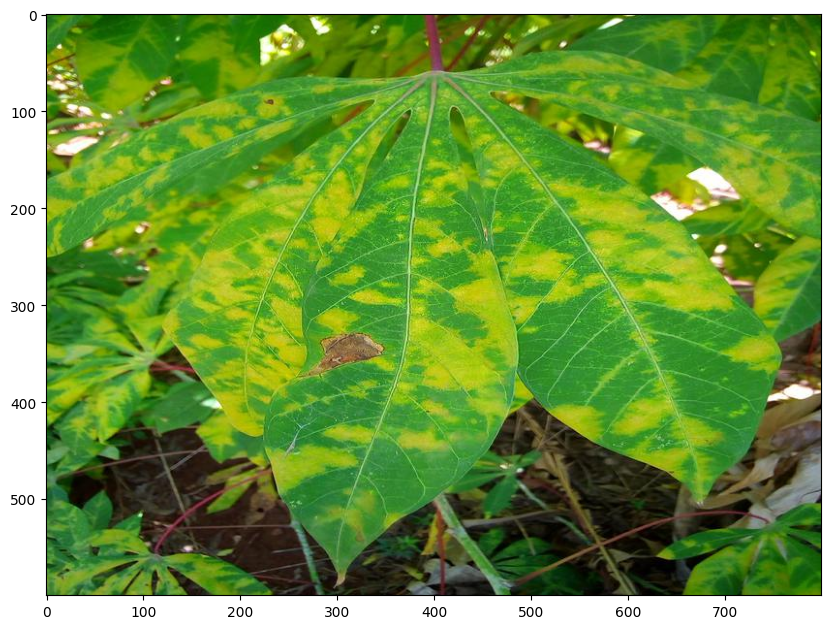

In [ ]:
plot_image(train_dataset[0])


In [ ]:
# Now, lets add some augmentations using one of the best
# augmentations library: albumentations
# Tez supports albumentations exclusively

train_aug = albumentations.Compose(
    [
        albumentations.RandomResizedCrop(256, 256),
        albumentations.Transpose(p=0.5),
        albumentations.HorizontalFlip(p=0.5),
        albumentations.VerticalFlip(p=0.5),
        albumentations.ShiftScaleRotate(p=0.5),
        # albumentations.Normalize(
        #    mean=[0.485, 0.456, 0.406],
        #    std=[0.229, 0.224, 0.225],
        #    max_pixel_value=255.0,
        #    p=1.0
        #)
    ]
)

# now, we set resize to None as we are doing
# resizing via augmentations
train_dataset = ImageDataset(
    image_paths=train_image_paths,
    targets=train_targets,
    augmentations=train_aug,
)


tensor(1)


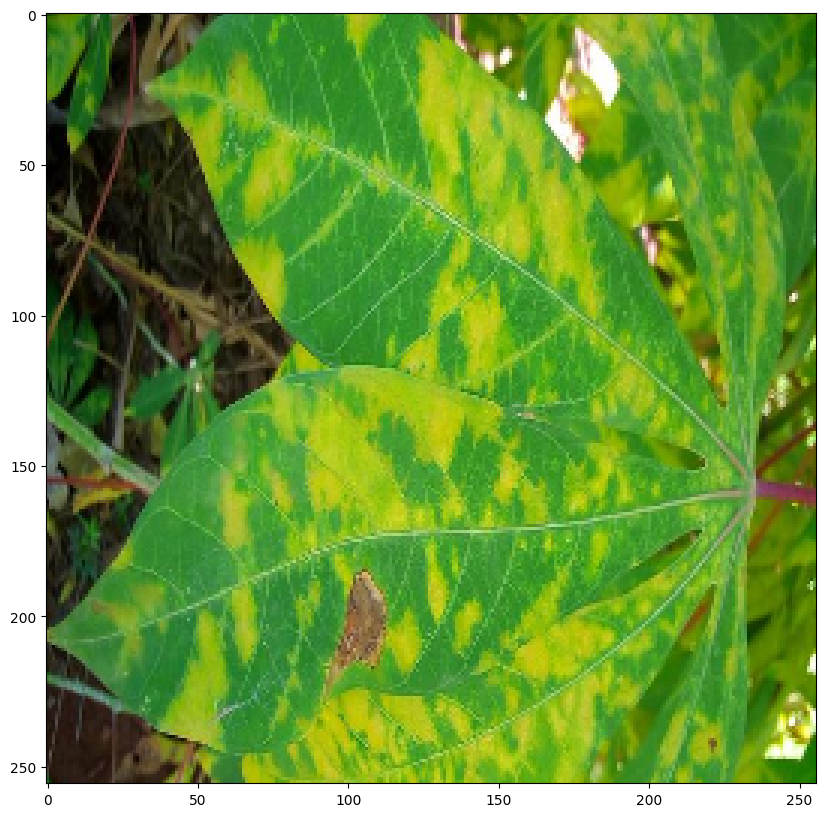

In [ ]:
plot_image(train_dataset[0])

In [ ]:
# Let's define a model now
# We inherit from tez.Model instead of nn.Module
# we have monitor_metrics if we want to monitor any metrics
# except the loss
# and we return 3 values in forward function.

class LeafModel(tez.Model):
    def __init__(self, num_classes,pretrained=True):
        super().__init__()

        self.convnet = torchvision.models.resnet18(pretrained=pretrained)
        self.convnet.fc = nn.Linear(512, num_classes)
        self.step_scheduler_after = "epoch"

    def loss(self, outputs, targets):
      if targets is None:
        return None
      return nn.CrossEntropyLoss()(outputs, targets)

    def monitor_metrics(self, outputs, targets):
        outputs = torch.argmax(outputs, dim=1).cpu().detach().numpy()
        targets = targets.cpu().detach().numpy()
        accuracy = metrics.accuracy_score(targets, outputs)
        return {"accuracy": accuracy}

    def fetch_optimizer(self):
        opt = torch.optim.Adam(self.parameters(), lr=1e-3)
        return opt

    def fetch_scheduler(self):
        sch = torch.optim.lr_scheduler.StepLR(self.optimizer, step_size=0.7)
        return sch

    def forward(self, image, targets=None):
        batch_size, _, _, _ = image.shape

        outputs = self.convnet(image)

        if targets is not None:
            loss = nn.CrossEntropyLoss()(outputs, targets)
            metrics = self.monitor_metrics(outputs, targets)
            return outputs, loss, metrics
        return outputs, None, None

In [ ]:
model = LeafModel(num_classes=dfx.label.nunique(), pretrained=True)


In [ ]:
model

LeafModel(
  (convnet): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_r

In [ ]:
image = train_dataset[0]["image"].unsqueeze(0)
target = train_dataset[0]["targets"].unsqueeze(0)


model(image, target)

(tensor([[ 0.9654, -0.0470,  0.7261, -0.2595, -0.9556]],
        grad_fn=<AddmmBackward0>),
 tensor(1.9643, grad_fn=<NllLossBackward0>),
 {'accuracy': 0.0})

In [ ]:
train_aug = albumentations.Compose([
            albumentations.RandomResizedCrop(256, 256),
            albumentations.Transpose(p=0.5),
            albumentations.HorizontalFlip(p=0.5),
            albumentations.VerticalFlip(p=0.5),
            albumentations.ShiftScaleRotate(p=0.5),
            albumentations.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
                max_pixel_value=255.0,
                p=1.0
            )], p=1.)

valid_aug = albumentations.Compose([
            albumentations.CenterCrop(256, 256, p=1.),
            albumentations.Resize(256, 256),
            albumentations.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
                max_pixel_value=255.0,
                p=1.0
            )], p=1.)

train_dataset = ImageDataset(
    image_paths=train_image_paths,
    targets=train_targets,
    augmentations=train_aug,
)

valid_dataset = ImageDataset(
    image_paths=valid_image_paths,
    targets=valid_targets,
    augmentations=valid_aug,
)

In [ ]:
es = EarlyStopping(
    monitor="valid_accuracy", model_path="model.bin", patience=2, mode="max"
)
model.fit(
    train_dataset,
    valid_dataset=valid_dataset,
    train_bs=32,
    valid_bs=64,
    device="cuda",
    epochs=5,
    callbacks=[es],
    fp16=True,
)

NOTE: This is old Model class and is deprecated. It will no longer be maintained! Please use version > 0.5.1. Its much better and supports multi-gpu training too!


100%|██████████| 34/34 [00:19<00:00,  1.78it/s, accuracy=0.71, loss=0.78, stage=valid]


AttributeError: 'LeafModel' object has no attribute 'config'

In [ ]:
test_dfx = pd.read_csv("/content/sample_submission.csv")
image_path = "/content/test_images/"
test_image_paths = [os.path.join(image_path, x) for x in test_dfx.image_id.values]
# fake targets
test_targets = test_dfx.label.values


test_aug = albumentations.Compose([
            albumentations.CenterCrop(256, 256, p=1.),
            albumentations.Resize(256, 256),
            albumentations.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
                max_pixel_value=255.0,
                p=1.0
            )], p=1.)

test_dataset = ImageDataset(
    image_paths=test_image_paths,
    targets=test_targets,
    resize=None,
    augmentations=test_aug,
)

In [ ]:
preds = model.predict(test_dataset, batch_size=32, n_jobs=-1, device="cuda")
final_preds = None
for p in preds:
    if final_preds is None:
        final_preds = p
    else:
        final_preds = np.vstack((final_preds, p))
final_preds = final_preds.argmax(axis=1)
test_dfx.label = final_preds
test_dfx.to_csv("submission.csv", index=False)